# 05 — ML Models
**Part D | Milestone 5**

Question: which classic regressors can predict a window's 1 s drift (`err_mag_m`) on a sequence they never saw, and is the training/tuning set-up honest?

This notebook **calls** the code in `src/vio_drift/models/ml/` and loads the models saved by `python scripts/train_ml.py`; nothing is re-implemented here. It runs validation and sanity checks on the set-up. Held-out scores and failure analysis are in notebook 06.

Set-up recap:
* **Outer loop** — leave-one-sequence-out (`splits.json`): 3 folds, each tests on one sequence.
* **Inner loop** — hyperparameters are grid-searched on the fold's two training sequences only, again holding out one whole sequence at a time (`tuning.py`).
* **Models** — mean baseline, unregularised linear regression (OLS), Ridge (L2), Lasso (L1), Random Forest.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import joblib
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vio_drift.models.ml.data import load_dataset, load_splits, split_xy, fold_frames
from vio_drift.models.ml.registry import model_specs, MODEL_NAMES

ROOT = Path.cwd().parent
config = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())
sequences = config["data"]["sequences"]
processed = ROOT / config["data"]["processed_dir"]
seed = int(config["seed"])
MODELS_DIR = ROOT / "models" / "ml"
METRICS = ROOT / "results" / "metrics"

TARGET = "err_mag_m"
df = load_dataset(processed, sequences, target=TARGET)
folds = load_splits(processed / "splits.json")

def saved(fold_id, model, target=TARGET):
    """Load a model written by scripts/train_ml.py."""
    return joblib.load(MODELS_DIR / f"{target}__{fold_id}__{model}.joblib")

print(df.shape, "| folds:", [f.fold_id for f in folds])

(1843, 108) | folds: ['leave_MH_01_easy', 'leave_MH_02_easy', 'leave_MH_03_medium']


## 1. The data each model sees

One row per 1 s window: 104 unscaled features plus the label. The label is tightly clustered around 0.185 m, so every model is fighting over a spread of about a centimetre.

In [2]:
df.groupby("seq_id")[TARGET].describe().round(4)

,count,mean,std,min,25%,50%,75%,max
seq_id,,,,,,,,
MH_01_easy,724.0,0.1859,0.0119,0.1399,0.1795,0.1875,0.1935,0.2220
MH_02_easy,596.0,0.1856,0.0131,0.1384,0.1800,0.1871,0.1943,0.2153
MH_03_medium,523.0,0.1813,0.0205,0.0967,0.1713,0.1804,0.1895,0.3008


## 2. Leakage checks

Two things must hold for every fold:
1. no window of the test sequence is in the training rows;
2. any scaler inside a saved model was fit on the **training** rows only — its stored mean must equal the training mean, not the mean of all three sequences.

In [3]:
for fold in folds:
    train, test = fold_frames(df, fold)
    assert set(train["seq_id"]).isdisjoint(test["seq_id"])

    X_train, _, _ = split_xy(train, TARGET)
    X_all, _, _ = split_xy(df, TARGET)
    print(f"{fold.fold_id:<20s} train={list(fold.train)} test={list(fold.test)}")
    for name in ["linear", "ridge", "lasso"]:
        scaler_mean = saved(fold.fold_id, name).named_steps["scaler"].mean_
        print(f"    {name:<13s} scaler = train mean: {np.allclose(scaler_mean, X_train.mean())}"
              f" | = pooled mean: {np.allclose(scaler_mean, X_all.mean())}")

leave_MH_01_easy     train=['MH_02_easy', 'MH_03_medium'] test=['MH_01_easy']
    linear        scaler = train mean: True | = pooled mean: False
    ridge         scaler = train mean: True | = pooled mean: False
    lasso         scaler = train mean: True | = pooled mean: False
leave_MH_02_easy     train=['MH_01_easy', 'MH_03_medium'] test=['MH_02_easy']
    linear        scaler = train mean: True | = pooled mean: False
    ridge         scaler = train mean: True | = pooled mean: False
    lasso         scaler = train mean: True | = pooled mean: False
leave_MH_03_medium   train=['MH_01_easy', 'MH_02_easy'] test=['MH_03_medium']
    linear        scaler = train mean: True | = pooled mean: False
    ridge         scaler = train mean: True | = pooled mean: False
    lasso         scaler = train mean: True | = pooled mean: False


## 3. Models and search grids

Each model's grid lives next to its builder (`baselines.py`, `random_forest.py`).

In [4]:
for spec in model_specs(seed):
    n = int(np.prod([len(v) for v in spec.param_grid.values()])) if spec.param_grid else 1
    print(f"{spec.name:<14s} {n:>2d} candidates  {spec.param_grid}")

mean            1 candidates  {}
linear          1 candidates  {}
ridge           8 candidates  {'ridge__alpha': [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0, 100000.0]}
lasso           6 candidates  {'lasso__alpha': [1e-06, 1e-05, 0.0001, 0.001, 0.01, 0.1]}
random_forest  27 candidates  {'max_depth': [None, 4, 8], 'min_samples_leaf': [1, 5, 20], 'max_features': [1.0, 'sqrt', 0.3]}


## 4. Tuning results (inner CV, training sequences only)

From `results/metrics/err_mag_m_tuning.csv`. The inner-CV MAE is what tuning *optimised*; it is not a test score.

In [5]:
tuning = pd.read_csv(METRICS / f"{TARGET}_tuning.csv")
display(tuning.pivot(index="model", columns="test_seq", values="inner_cv_mae").loc[list(MODEL_NAMES)].round(4))
tuning[["fold_id", "model", "best_params"]]

test_seq,MH_01_easy,MH_02_easy,MH_03_medium
model,,,
mean,0.0127,0.0124,0.0094
linear,0.0454,0.0280,0.0084
ridge,0.0123,0.0120,0.0072
lasso,0.0123,0.0119,0.0071
random_forest,0.0129,0.0123,0.0070


,fold_id,model,best_params
0,leave_MH_01_easy,mean,{}
1,leave_MH_01_easy,linear,{}
2,leave_MH_01_easy,ridge,"{""ridge__alpha"": 1000.0}"
3,leave_MH_01_easy,lasso,"{""lasso__alpha"": 0.001}"
4,leave_MH_01_easy,random_forest,"{""max_depth"": 8, ""max_features"": ""sqrt"", ""min_..."
5,leave_MH_02_easy,mean,{}
6,leave_MH_02_easy,linear,{}
7,leave_MH_02_easy,ridge,"{""ridge__alpha"": 1000.0}"
8,leave_MH_02_easy,lasso,"{""lasso__alpha"": 0.001}"
9,leave_MH_02_easy,random_forest,"{""max_depth"": 4, ""max_features"": ""sqrt"", ""min_..."


## 5. Sanity check — shuffled labels

If the pipeline leaked test information, a model trained on **shuffled** labels could still look good on the held-out sequence. Trained on noise, a correct pipeline should do no better than the mean baseline.

In [6]:
from sklearn.base import clone
from vio_drift.evaluation.metrics import mae

rng = np.random.default_rng(seed)
rows = []
for fold in folds:
    train, test = fold_frames(df, fold)
    X_tr, y_tr, _ = split_xy(train, TARGET)
    X_te, y_te, _ = split_xy(test, TARGET)
    rf_shuffled = clone(saved(fold.fold_id, "random_forest")).fit(X_tr, rng.permutation(y_tr))
    rows.append({
        "test_seq": fold.test[0],
        "mean_baseline_mae": mae(y_te, np.full(len(y_te), y_tr.mean())),
        "rf_real_labels_mae": mae(y_te, saved(fold.fold_id, "random_forest").predict(X_te)),
        "rf_shuffled_labels_mae": mae(y_te, rf_shuffled.predict(X_te)),
    })
pd.DataFrame(rows).round(4)

,test_seq,mean_baseline_mae,rf_real_labels_mae,rf_shuffled_labels_mae
0,MH_01_easy,0.0094,0.0077,0.0100
1,MH_02_easy,0.0101,0.0078,0.0101
2,MH_03_medium,0.0145,0.0150,0.0144


## 6. Sanity check — reproducibility

Refitting a saved Random Forest's settings on the same training rows must give identical predictions (fixed `seed` in `config.yaml`).

In [7]:
for fold in folds:
    train, test = fold_frames(df, fold)
    X_tr, y_tr, _ = split_xy(train, TARGET)
    X_te, _, _ = split_xy(test, TARGET)
    rf = saved(fold.fold_id, "random_forest")
    same = np.allclose(clone(rf).fit(X_tr, y_tr).predict(X_te), rf.predict(X_te))
    print(f"{fold.fold_id:<20s} refit reproduces saved predictions: {same}")

leave_MH_01_easy     refit reproduces saved predictions: True


leave_MH_02_easy     refit reproduces saved predictions: True


leave_MH_03_medium   refit reproduces saved predictions: True


## 7. Ridge regularisation curve

Re-running `tune()` for Ridge on one fold shows the inner-CV MAE across the alpha grid. Strong shrinkage wins, and the chosen alpha sits inside the grid, not at its edge.

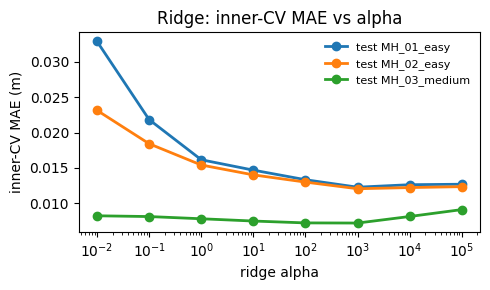

In [8]:
from vio_drift.models.ml.tuning import tune

spec = next(s for s in model_specs(seed) if s.name == "ridge")
fig, ax = plt.subplots(figsize=(5, 3))
for fold in folds:
    train, _ = fold_frames(df, fold)
    X_tr, y_tr, g_tr = split_xy(train, TARGET)
    res = tune(spec.build(), spec.param_grid, X_tr, y_tr, g_tr)
    alphas = [p["ridge__alpha"] for p in res.cv_results["params"]]
    ax.plot(alphas, res.cv_results["mean_test_mae"], marker="o", lw=2, label=f"test {fold.test[0]}")
ax.set_xscale("log"); ax.set_xlabel("ridge alpha"); ax.set_ylabel("inner-CV MAE (m)")
ax.set_title("Ridge: inner-CV MAE vs alpha"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

## 8. OLS vs Ridge (L2) vs Lasso (L1) — what the penalty buys

OLS is the linear model with no penalty; Ridge adds `alpha·Σw²`; Lasso adds `alpha·Σ|w|`. All three are trained on the same folds. Two things to compare:

1. **Weight sizes.** With near-duplicate features (17 pairs with |r| > 0.95), least squares can give a pair huge weights of opposite sign that cancel on the training rows. The label itself is only ~0.19 m with a spread of ~0.015 m, so any weight far above that is a warning sign.
2. **Inner-CV MAE** — the score tuning sees on a held-out *training* sequence, before the test sequence is touched.

In [9]:
rows = []
for fold in folds:
    for name in ["linear", "ridge", "lasso"]:
        w = saved(fold.fold_id, name)[-1].coef_   # last pipeline step; features are standardised
        rows.append({"test_seq": fold.test[0], "model": name,
                     "max |w|": np.abs(w).max(), "median |w|": np.median(np.abs(w)),
                     "sum of w": w.sum(), "non-zero weights": int(np.sum(w != 0))})
weights = pd.DataFrame(rows).set_index(["test_seq", "model"])
weights.style.format({"max |w|": "{:.4f}", "median |w|": "{:.4f}", "sum of w": "{:.4f}"})

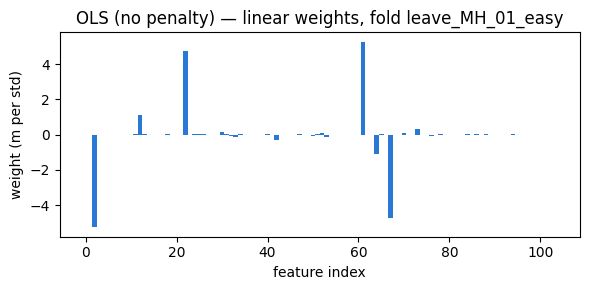

In [10]:
fold = folds[0]
w = saved(fold.fold_id, "linear")[-1].coef_
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(len(w)), w, width=1.0, color="#2a78d6")
ax.set_xlabel("feature index"); ax.set_ylabel("weight (m per std)")
ax.set_title(f"OLS (no penalty) — linear weights, fold {fold.fold_id}")
fig.tight_layout(); plt.show()

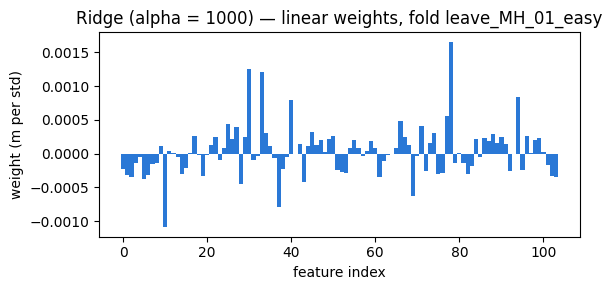

In [11]:
fold = folds[0]
w = saved(fold.fold_id, "ridge")[-1].coef_
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(len(w)), w, width=1.0, color="#2a78d6")
ax.set_xlabel("feature index"); ax.set_ylabel("weight (m per std)")
ax.set_title(f"Ridge (alpha = 1000) — linear weights, fold {fold.fold_id}")
fig.tight_layout(); plt.show()

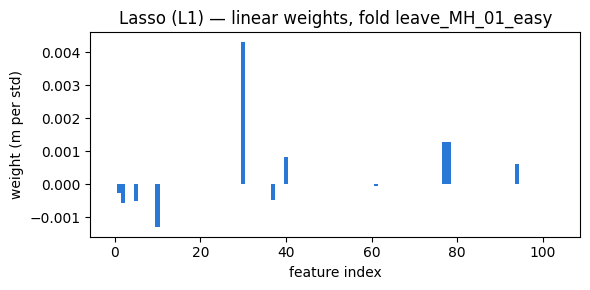

In [12]:
fold = folds[0]
w = saved(fold.fold_id, "lasso")[-1].coef_
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(len(w)), w, width=1.0, color="#2a78d6")
ax.set_xlabel("feature index"); ax.set_ylabel("weight (m per std)")
ax.set_title(f"Lasso (L1) — linear weights, fold {fold.fold_id}")
fig.tight_layout(); plt.show()

In [13]:
from vio_drift.features.build_features import feature_names
feats = np.array(feature_names())
kept = pd.DataFrame({fold.test[0]: pd.Series(saved(fold.fold_id, "lasso")[-1].coef_, index=feats)
                     for fold in folds})
kept = kept[(kept != 0).any(axis=1)]
kept.loc[kept.abs().max(axis=1).sort_values(ascending=False).index].round(5)

,MH_01_easy,MH_02_easy,MH_03_medium
ax_rms,0.00000,0.00000,0.00576
ax_mean,0.00432,0.00320,0.00000
az_spec_entropy,0.00129,0.00232,0.00087
gy_mean,-0.00130,-0.00095,-0.00010
acc_mag_mean,0.00129,0.00101,0.00079
ay_mean,0.00084,0.00000,0.00000
ax_spec_entropy,0.00000,0.00001,0.00074
corr_gy_gz,0.00061,0.00000,0.00000
gx_var,-0.00056,-0.00000,-0.00000
gx_max,-0.00049,-0.00053,-0.00031


In [14]:
tuning.pivot(index="model", columns="test_seq", values="inner_cv_mae").loc[["mean", "linear", "ridge", "lasso"]].round(4)

test_seq,MH_01_easy,MH_02_easy,MH_03_medium
model,,,
mean,0.0127,0.0124,0.0094
linear,0.0454,0.0280,0.0084
ridge,0.0123,0.0120,0.0072
lasso,0.0123,0.0119,0.0071


**Reading it.** OLS weights reach about 5–7 m per standard deviation, and they nearly cancel (their sum is small next to the largest weight) — the signature of collinear features fighting each other. Ridge's weights are a few thousand times smaller. Lasso goes further: its L1 penalty sets **all but 8–11 of the 104 weights to exactly zero**, and the features it keeps (`ax_mean`/`ax_rms`, `acc_mag_mean`, `az_spec_entropy`, `gy_mean`) are the ones permutation importance ranks highest in notebook 06. Inner CV catches OLS's problem before any test data is used: it scores 0.045 and 0.028 m on the first two folds, more than twice the mean baseline, while Ridge and Lasso stay near 0.012 m. Held-out results (notebook 06): OLS is worse than the mean baseline on average; Lasso, Ridge and Random Forest are tied for best.

## What we checked

* **No leakage:** each fold's test sequence is absent from its training rows, and every saved scaler matches the training-sequence mean, not the pooled mean.
* **Shuffled-label control:** a Random Forest trained on permuted labels scores no better than the mean baseline on held-out data, so the real models' gains come from real signal.
* **Reproducible:** refitting from saved settings reproduces the saved predictions exactly.
* **Tuning is sane:** the Ridge optimum (alpha = 1000) is inside the grid, and heavy shrinkage is preferred — consistent with 104 highly collinear features.
* **The penalty is needed:** unregularised OLS gives weights thousands of times larger than Ridge's that nearly cancel, and its inner-CV MAE is more than twice the mean baseline's on two folds. Lasso keeps only 8–11 of 104 features.

Held-out results and failure analysis: notebook 06.